In [ ]:
!pip install transformers torch scikit-learn

In [ ]:
!pip install "datasets<2.20.0"


INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 12.2 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    F

In [ ]:
!pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=f703693bdacec6f0cccfeeeca624b2b7a7181bd6e64fa1f47ffdf13846d5d5b6
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
!pip install matplotlib seaborn

In [ ]:
#semente
import os
import random
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from transformers import ElectraTokenizer, ElectraForSequenceClassification
from datasets import load_dataset
from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
    print(f"[OK] semente fixada em: {seed}")

set_seed(42)

[OK] semente fixada em: 42


In [ ]:
# baixando e limpando
print("baixando dataset")
dataset_train = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"train": "mental_heath_unbanlanced.csv"})
dataset_test = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"test": "mental_health_combined_test.csv"})

df_train = pd.DataFrame(dataset_train['train'])
df_test = pd.DataFrame(dataset_test['test'])

df_total = pd.concat([df_train, df_test], ignore_index=True)
df_total = df_total[df_total['status'].isin(['Depression', 'Normal'])].copy()
df_total['label'] = df_total['status'].map({'Normal': 0, 'Depression': 1})
df_total = df_total.rename(columns={'text': 'texto_limpo'})

def limpar_texto_redes_sociais(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'\@\w+', '', texto)
    texto = re.sub(r'[^\w\s]', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

print("limpando")
df_total['texto_limpo'] = df_total['texto_limpo'].apply(limpar_texto_redes_sociais)

qtd_antes = len(df_total)
df_total = df_total[df_total['texto_limpo'].str.len() > 5].copy()
df_total = df_total.drop_duplicates(subset=['texto_limpo']).reset_index(drop=True)
qtd_depois = len(df_total)

print(f"{qtd_antes - qtd_depois} textos duplicados excluidos")
print(f"total final de registros: {qtd_depois}")

baixando dataset
limpando
792 textos duplicados excluidos
total final de registros: 32601


In [ ]:
#dividindo
df_treino, df_teste = train_test_split(
    df_total,
    test_size=0.20,
    random_state=42,
    stratify=df_total['label']
)
print(f"Treino: {len(df_treino)} | Teste: {len(df_teste)}")

print("carregando tokenizador")
tokenizer = ElectraTokenizer.from_pretrained('google/electra-base-discriminator')
train_encodings = tokenizer(df_treino['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
test_encodings = tokenizer(df_teste['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
print("tokenização concluída")

Treino: 26080 | Teste: 6521
carregando tokenizador


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenização concluída


In [ ]:
#organização
class OuraflaDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

print("criando objetos")
train_dataset = OuraflaDataset(train_encodings, df_treino['label'].tolist())
test_dataset = OuraflaDataset(test_encodings, df_teste['label'].tolist())

print("empacotando os dados em lotes (Batch Size = 32)")
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
print(f" Treino: {len(train_loader)} lotes | Teste: {len(test_loader)} lotes.\n")

print("vendo o primeiro lote")
primeiro_lote = next(iter(train_loader))
print("Chaves contidas no lote: ", primeiro_lote.keys())
print("Dimensão dos input_ids: ", primeiro_lote['input_ids'].shape)
print("Dimensão da attention_mask: ", primeiro_lote['attention_mask'].shape)
print("Dimensão dos rótulos: ", primeiro_lote['labels'].shape)
print("\nRótulos das 32 amostras deste lote (0 = Normal, 1 = Depressão):")
print(primeiro_lote['labels'])

criando objetos
empacotando os dados em lotes (Batch Size = 32)
 Treino: 815 lotes | Teste: 204 lotes.

vendo o primeiro lote
Chaves contidas no lote:  dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])
Dimensão dos input_ids:  torch.Size([32, 128])
Dimensão da attention_mask:  torch.Size([32, 128])
Dimensão dos rótulos:  torch.Size([32])

Rótulos das 32 amostras deste lote (0 = Normal, 1 = Depressão):
tensor([0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1,
        0, 1, 0, 1, 0, 0, 0, 1])


In [ ]:
# carregando o modelo
print("baixando o modelo ")
modelo_electra = ElectraForSequenceClassification.from_pretrained('google/electra-base-discriminator', num_labels=2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
modelo_electra.to(device)
print(f"Modelo enviado para: {device}")

baixando o modelo 


config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: google/electra-base-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
electra.embeddings_project.bias                   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
electra.embeddings_project.weight                 | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Modelo enviado para: cuda


In [ ]:
#treinamento
otimizador = AdamW(modelo_electra.parameters(), lr=2e-5)
epochs = 3

print("iniciando o treinamento")
for epoch in range(epochs):
    modelo_electra.train()
    total_loss = 0

    for step, batch in enumerate(train_loader):
        otimizador.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_electra(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        otimizador.step()

        if step % 100 == 0:
            print(f"Época {epoch + 1}/{epochs} | Lote {step}/{len(train_loader)} | Loss: {loss.item():.4f}")

    print(f"--- Fim da Época {epoch + 1} | Perda Média: {total_loss / len(train_loader):.4f} ---")

print("treinamento concluído")

iniciando o treinamento
Época 1/3 | Lote 0/815 | Loss: 0.6733
Época 1/3 | Lote 100/815 | Loss: 0.1038
Época 1/3 | Lote 200/815 | Loss: 0.1078
Época 1/3 | Lote 300/815 | Loss: 0.1229
Época 1/3 | Lote 400/815 | Loss: 0.0815
Época 1/3 | Lote 500/815 | Loss: 0.1776
Época 1/3 | Lote 600/815 | Loss: 0.0428
Época 1/3 | Lote 700/815 | Loss: 0.1622
Época 1/3 | Lote 800/815 | Loss: 0.1280
--- Fim da Época 1 | Perda Média: 0.1695 ---
Época 2/3 | Lote 0/815 | Loss: 0.0421
Época 2/3 | Lote 100/815 | Loss: 0.0177
Época 2/3 | Lote 200/815 | Loss: 0.0577
Época 2/3 | Lote 300/815 | Loss: 0.1722
Época 2/3 | Lote 400/815 | Loss: 0.0195
Época 2/3 | Lote 500/815 | Loss: 0.0086
Época 2/3 | Lote 600/815 | Loss: 0.0217
Época 2/3 | Lote 700/815 | Loss: 0.0203
Época 2/3 | Lote 800/815 | Loss: 0.0884
--- Fim da Época 2 | Perda Média: 0.0880 ---
Época 3/3 | Lote 0/815 | Loss: 0.0605
Época 3/3 | Lote 100/815 | Loss: 0.2578
Época 3/3 | Lote 200/815 | Loss: 0.0045
Época 3/3 | Lote 300/815 | Loss: 0.0740
Época 3/3 | 

Acurácia: 96.29%
Precisão: 0.9657
Recall: 0.9504
F1-Score: 0.9580

               precision    recall  f1-score   support

   Normal (0)       0.96      0.97      0.97      3617
Depressão (1)       0.97      0.95      0.96      2904

     accuracy                           0.96      6521
    macro avg       0.96      0.96      0.96      6521
 weighted avg       0.96      0.96      0.96      6521



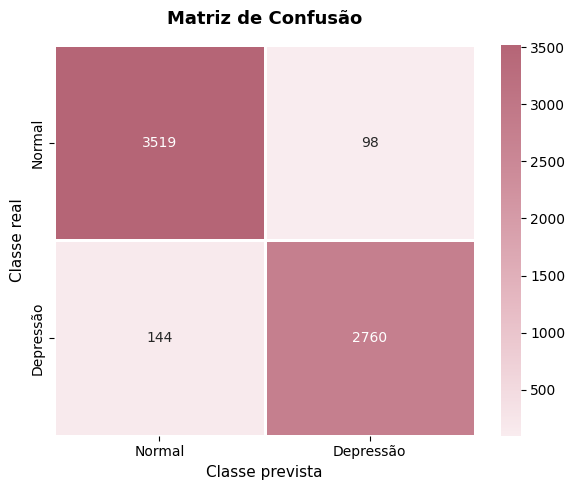

In [ ]:
#avaliação
modelo_electra.eval()
previsoes_finais, rotulos_reais = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_electra(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        previsoes_finais.extend(preds.cpu().numpy())
        rotulos_reais.extend(labels.cpu().numpy())

acuracia = accuracy_score(rotulos_reais, previsoes_finais)
prec = precision_score(rotulos_reais, previsoes_finais)
rec = recall_score(rotulos_reais, previsoes_finais)
f1 = f1_score(rotulos_reais, previsoes_finais)


print(f"Acurácia: {acuracia * 100:.2f}%")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}\n")
print(classification_report(rotulos_reais, previsoes_finais, target_names=['Normal (0)', 'Depressão (1)']))

cm = confusion_matrix(rotulos_reais, previsoes_finais)
cor_electra2 = "#B56576"
cores_electra2 = ["#F9ECEF", "#E6BAC3", "#CD8C9A", cor_electra2]
cmap_electra2 = LinearSegmentedColormap.from_list("ELECTRA2", cores_electra2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=cmap_electra2,
    xticklabels=['Normal', 'Depressão'],
    yticklabels=['Normal', 'Depressão'],
    linewidths=1,
    linecolor='white'
)
plt.xlabel('Classe prevista', fontsize=11)
plt.ylabel('Classe real', fontsize=11)
plt.title('Matriz de Confusão', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

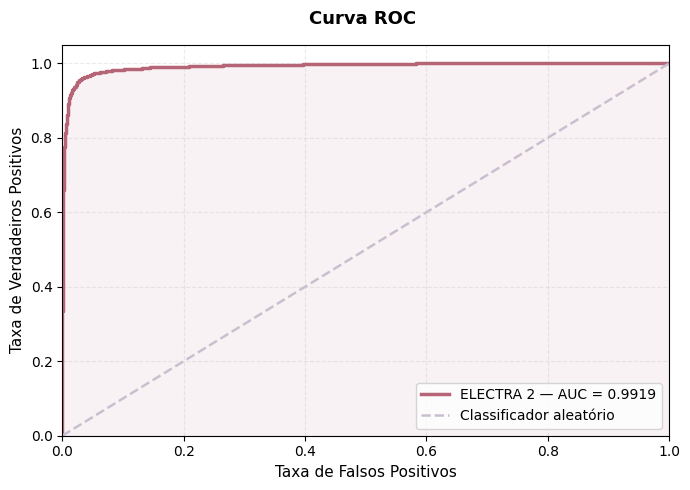

AUC Final: 0.9919


In [ ]:
#roc e auc
probabilidades, verdadeiros = [], []

modelo_electra.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_electra(input_ids=input_ids, attention_mask=attention_mask)
        probs = F.softmax(outputs.logits, dim=1)

        probabilidades.extend(probs[:, 1].cpu().numpy())
        verdadeiros.extend(labels.cpu().numpy())

fpr, tpr, limiares = roc_curve(verdadeiros, probabilidades)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="#B56576", lw=2.5, label=f'ELECTRA 2 — AUC = {roc_auc:.4f}')
plt.fill_between(fpr, tpr, alpha=0.08, color="#B56576")
plt.plot([0, 1], [0, 1], color="#C9C0CF", lw=1.8, linestyle='--', label='Classificador aleatório')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos', fontsize=11)
plt.ylabel('Taxa de Verdadeiros Positivos', fontsize=11)
plt.title('Curva ROC ', fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", frameon=True)
plt.grid(alpha=0.25, linestyle='--')
plt.tight_layout()
plt.show()

print(f"AUC Final: {roc_auc:.4f}")

TEXTO ANALISADO — ELECTRA 2
time to sleep again good morning everyone

Rótulo Real: 0 (Normal)



TypeError: unhashable type: 'numpy.ndarray'

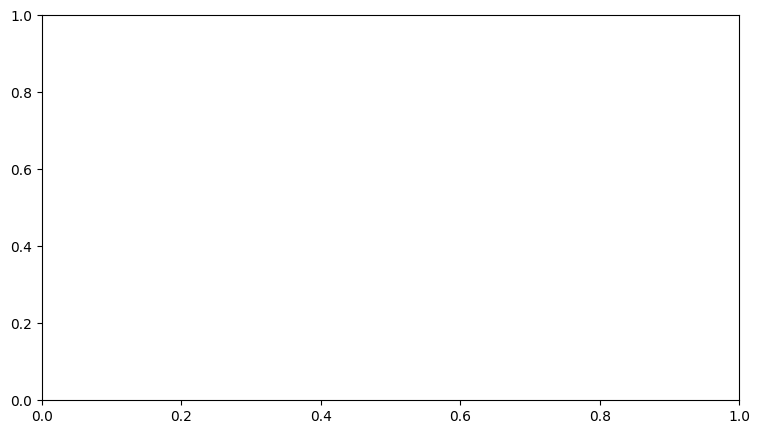

In [ ]:
#lime
def predict_probs_lime(texts):
    modelo_electra.eval()
    todas_probs = []
    for i in range(0, len(texts), 32):
        lote_textos = texts[i:i + 32]
        inputs = tokenizer(lote_textos, padding='max_length', truncation=True, max_length=128, return_tensors="pt")
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        with torch.no_grad():
            outputs = modelo_electra(input_ids=input_ids, attention_mask=attention_mask)
            probs = F.softmax(outputs.logits, dim=1)
            todas_probs.append(probs.cpu().numpy())
    return np.vstack(todas_probs)

explainer = LimeTextExplainer(class_names=['Normal', 'Depressão'], random_state=42)

idx = 72
texto_amostra = str(df_teste.iloc[idx]['texto_limpo'])
rotulo_real = int(df_teste.iloc[idx]['label'])

print("=" * 60)
print("TEXTO ANALISADO — ELECTRA 2")
print("=" * 60)
print(f"{texto_amostra}\n")
print(f"Rótulo Real: {rotulo_real} ({'Depressão' if rotulo_real == 1 else 'Normal'})\n")

exp = explainer.explain_instance(texto_amostra, predict_probs_lime, num_features=10, num_samples=500)

lista_features = exp.as_list()
palavras = [item[0] for item in lista_features]
pesos = np.array([item[1] for item in lista_features])

cor_electra2_pos = "#B56576"
cor_electra2_neg = "#6D3B47"
cor_zero = "#B8B8B8"

plt.figure(figsize=(9, 5))
cores = [cor_electra2_pos if peso > 0 else cor_electra2_neg for peso in pesos]
plt.barh(palavras[::-1], pesos[::-1], color=cores[::-1], edgecolor='none')
plt.axvline(0, color=cor_zero, linewidth=1.2)
plt.xlabel('Impacto na decisão do modelo', fontsize=11)
plt.ylabel('Palavras (features)', fontsize=11)
plt.title(f'Explicação LIME  (Amostra #{idx})', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.25)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

css_electra2_darkmode = """ """
display(HTML(css_electra2_darkmode))
exp.show_in_notebook(text=True)